### Predict whether a mammogram mass is benign or malignant

We'll be using the "mammographic masses" public dataset from the UCI repository (source: https://archive.ics.uci.edu/ml/datasets/Mammographic+Mass)

This data contains 961 instances of masses detected in mammograms, and contains the following attributes:


   1. BI-RADS assessment: 1 to 5 (ordinal)  
   2. Age: patient's age in years (integer)
   3. Shape: mass shape: round=1 oval=2 lobular=3 irregular=4 (nominal)
   4. Margin: mass margin: circumscribed=1 microlobulated=2 obscured=3 ill-defined=4 spiculated=5 (nominal)
   5. Density: mass density high=1 iso=2 low=3 fat-containing=4 (ordinal)
   6. Severity: benign=0 or malignant=1 (binominal)
   
N/B:
BI-RADS is an assesment of how confident the severity classification is; it is not a "predictive" attribute and so we will discard it. The age, shape, margin, and density attributes are the features that we will build our model with, and "severity" is the classification we will attempt to predict based on those attributes.

Although "shape" and "margin" are nominal data types, which sklearn typically doesn't deal with well, they are close enough to ordinal that we shouldn't just discard them. The "shape" for example is ordered increasingly from round to irregular.

A lot of unnecessary anguish and surgery arises from false positives arising from mammogram results. If we can build a better way to interpret them through supervised machine learning, it could improve a lot of lives.

---

Apply several different supervised machine learning techniques to this data set, and see which one yields the highest accuracy as measured with K-Fold cross validation.

* Decision tree
* Random forest
* KNN
* Naive Bayes
* SVM
* Logistic Regression
* Neural network

#### Data preparation

In [12]:
import pandas as pd

masses = pd.read_csv('mammographic_masses.data.txt')
masses.head()

,5,67,3,5.1,3.1,1
0,4,43,1,1,?,1
1,5,58,4,5,3,1
2,4,28,1,1,3,0
3,5,74,1,5,?,1
4,4,65,1,?,3,0


In [13]:
masses = pd.read_csv('mammographic_masses.data.txt', na_values=['?'], names=['BI-RADS', 'Age', 'Shape', 'Margin', 'Density', 'Severity'])
masses.head()

,BI-RADS,Age,Shape,Margin,Density,Severity
0,5.0,67.0,3.0,5.0,3.0,1
1,4.0,43.0,1.0,1.0,NaN,1
2,5.0,58.0,4.0,5.0,3.0,1
3,4.0,28.0,1.0,1.0,3.0,0
4,5.0,74.0,1.0,5.0,NaN,1


In [14]:
masses.describe()

,BI-RADS,Age,Shape,Margin,Density,Severity
count,959.000000,956.000000,930.000000,913.000000,885.000000,961.000000
mean,4.348279,55.487448,2.721505,2.796276,2.910734,0.463059
std,1.783031,14.480131,1.242792,1.566546,0.380444,0.498893
min,0.000000,18.000000,1.000000,1.000000,1.000000,0.000000
25%,4.000000,45.000000,2.000000,1.000000,3.000000,0.000000
50%,4.000000,57.000000,3.000000,3.000000,3.000000,0.000000
75%,5.000000,66.000000,4.000000,4.000000,3.000000,1.000000
max,55.000000,96.000000,4.000000,5.000000,4.000000,1.000000


In [15]:
masses.info()

<class 'pandas.DataFrame'>
RangeIndex: 961 entries, 0 to 960
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   BI-RADS   959 non-null    float64
 1   Age       956 non-null    float64
 2   Shape     930 non-null    float64
 3   Margin    913 non-null    float64
 4   Density   885 non-null    float64
 5   Severity  961 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 45.2 KB


In [7]:
# masses.loc[(masses['BI-RADS'].isnull()) |
#            (masses['Age'].isnull()) |
#            (masses['Shape'].isnull()) |
#            (masses['Margin'].isnull()) |
#            (masses['Density'].isnull())]

In [16]:
## compare means between rows with missing values and those without to see if there is a significant difference in the two groups

cols = ['BI-RADS', 'Age', 'Shape', 'Margin', 'Density']
flag = masses[cols].isnull().any(axis=1) # (true if any rows across all the columns has a missing value, false otherwise)
masses.groupby(flag).agg(['mean', 'count'])

BI-RADS              Age           Shape          Margin        \
           mean count       mean count      mean count      mean count   
False  4.393976   830  55.781928   830  2.781928   830  2.813253   830   
True   4.054264   129  53.547619   126  2.220000   100  2.626506    83   

        Density        Severity        
           mean count      mean count  
False  2.915663   830  0.485542   830  
True   2.836364    55  0.320611   131

In [17]:
from scipy.stats import chi2_contingency
ct = pd.crosstab(flag, masses['Severity']) # contingency table for missing values flag vs Severity (the classification target)
chi2_contingency(ct)[1]   # determine p-value between the two groups (rows with missing values and those without) 

np.float64(0.0006169581929478813)

- 131/961 (~14%) missing data, so dropping rows may lead to a substantial information loss and bias the model
- difference between data missingness (flag) and Severity (classification target) is Significant (p-value = 0.0006 < 0.05), so dropping rows with missing values would actually be Significant information loss
- so imputing instead -- can us mode for categorical features and median for continuous features (lest outliers skew the mean), or better yet, use KNNImputer (better imputation approach i.t.o accuracy)

N/B: train/test split first before imputation to avoid data leakage (apply fit_transform for train, only transform for test)

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

features = ['BI-RADS', 'Age', 'Shape', 'Margin', 'Density']

X = masses[features]
y = masses['Severity']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler =  StandardScaler()
imputer = KNNImputer(n_neighbors=5)

X_train_imp = scaler.inverse_transform(imputer.fit_transform(scaler.fit_transform(X_train))) # use scaler.inverse to return the imputed values to their original scale
X_test_imp = scaler.inverse_transform(imputer.transform(scaler.transform(X_test)))

X_train_imp = pd.DataFrame(X_train_imp, columns=features, index=X_train.index)
X_test_imp = pd.DataFrame(X_test_imp, columns=features, index=X_test.index)

X_train_imp = X_train_imp.round() # return to whole numbers (similar to original dataset)
X_test_imp = X_test_imp.round()

X_train_imp.isnull().sum(), X_test_imp.isnull().sum()


(BI-RADS    0
 Age        0
 Shape      0
 Margin     0
 Density    0
 dtype: int64,
 BI-RADS    0
 Age        0
 Shape      0
 Margin     0
 Density    0
 dtype: int64)

In [33]:
X_train_imp.head()
# X_train_imp.describe()
# X_test_imp.info()

,BI-RADS,Age,Shape,Margin,Density
441,5.0,56.0,2.0,3.0,3.0
626,5.0,79.0,4.0,4.0,3.0
796,5.0,58.0,4.0,4.0,2.0
287,4.0,39.0,4.0,3.0,3.0
193,4.0,41.0,1.0,1.0,3.0


Checking for class distributions
- 0.54 B vs 0.46 M for both train and test sets (due to using stratify=y in train_test_split)
>> skew is mild (only 7% skew towards B), no need to use SMOTE or other techniques to balance the classes

In [31]:
y_train.value_counts()
y_train.value_counts(normalize=True)

# y_test.value_counts()
# y_test.value_counts(normalize=True)

Severity
0    0.536458
1    0.463542
Name: proportion, dtype: float64

---

### Decision Trees

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=1)
tree.fit(X_train_imp, y_train) 

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

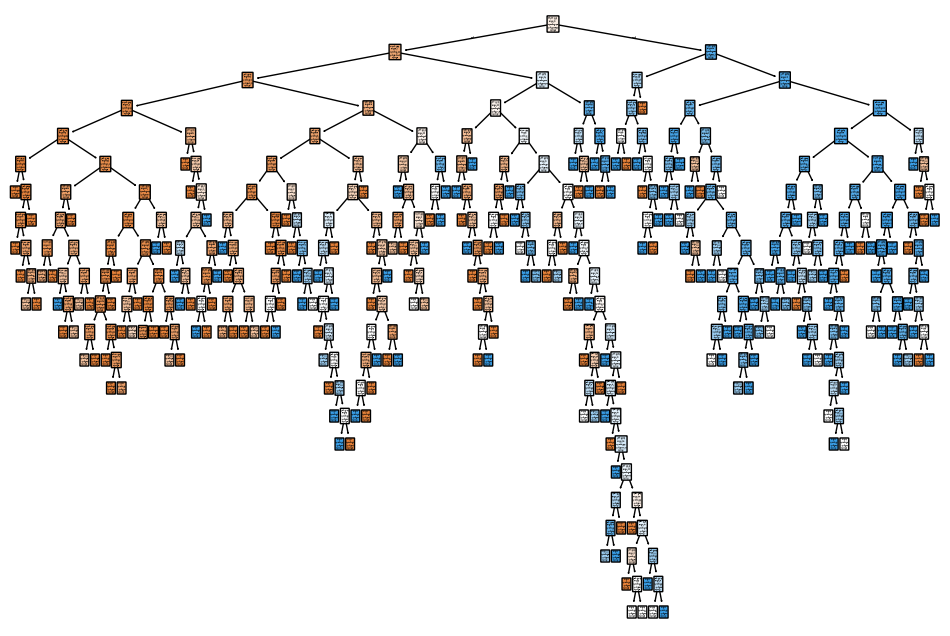

In [83]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=features, class_names=['B', 'M'], filled=True, rounded=True)
plt.show()

>> Decision trees are induced to overfit - to further improve performance this would require pruning and hyperparameter tuning (e.g. max_depth, min_samples_split, min_samples_leaf, etc.)

In [117]:
# using K-fold validation

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(tree, X_train_imp, y_train, cv=10)

print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {tree.score(X_test_imp, y_test)}')

Training cv_score: 0.7485816814764183
Testing score: 0.7772020725388601


RandomForestClassifier instead:

In [118]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=10, random_state=1)
rf.fit(X_train_imp, y_train)

cv_scores = cross_val_score(rf, X_train_imp, y_train, cv=10)

print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {rf.score(X_test_imp, y_test)}')

Training cv_score: 0.7837662337662338
Testing score: 0.7875647668393783


### SVM

In [120]:
from sklearn import svm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svc_lin = make_pipeline(StandardScaler(), svm.SVC(kernel='linear', C=1.0, random_state=1))
svc_lin.fit(X_train_imp, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['BI-RADS','Age','Shape','Margin','Density']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [121]:
cv_scores = cross_val_score(svc_lin, X_train_imp, y_train, cv=10)

print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {svc_lin.score(X_test_imp, y_test)}')

Training cv_score: 0.8241626794258374
Testing score: 0.8290155440414507


##### Trying different kernels

In [122]:
C = 1.0
svc_rbf = make_pipeline(StandardScaler(), svm.SVC(kernel='rbf', C=1.0, random_state=1))
svc_rbf.fit(X_train_imp, y_train)

cv_scores = cross_val_score(svc_rbf, X_train_imp, y_train, cv=10)
print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {svc_rbf.score(X_test_imp, y_test)}')

Training cv_score: 0.8215652768284347
Testing score: 0.8134715025906736


In [123]:
svc_sig = make_pipeline(StandardScaler(), svm.SVC(kernel='sigmoid', C=1.0, random_state=1))
svc_sig.fit(X_train_imp, y_train)

cv_scores = cross_val_score(svc_sig, X_train_imp, y_train, cv=10)
print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {svc_sig.score(X_test_imp, y_test)}')

Training cv_score: 0.7604921394395079
Testing score: 0.7668393782383419


In [124]:
svc_poly = make_pipeline(StandardScaler(), svm.SVC(kernel='poly', C=1.0, random_state=1))
svc_poly.fit(X_train_imp, y_train)

cv_scores = cross_val_score(svc_poly, X_train_imp, y_train, cv=10)
print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {svc_poly.score(X_test_imp, y_test)}')

Training cv_score: 0.813755980861244
Testing score: 0.8186528497409327


### KNN

In [125]:
from sklearn import neighbors

knn = make_pipeline(StandardScaler(), neighbors.KNeighborsClassifier(n_neighbors=15))
knn.fit(X_train_imp, y_train)

cv_scores = cross_val_score(knn, X_train_imp, y_train, cv=10)

print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {knn.score(X_test_imp, y_test)}')

Training cv_score: 0.8150717703349282
Testing score: 0.8031088082901554


In [105]:
# trying different values of k for KNN

scores = []
for n in range(1,50):
    knn = make_pipeline(StandardScaler(), neighbors.KNeighborsClassifier(n_neighbors=n))
    cv_scores = cross_val_score(knn, X_train_imp, y_train, cv=10)
    scores.append(cv_scores.mean())

best_k = scores.index(max(scores)) + 1
print(f'Best k={best_k}, mean cv score={max(scores)}')


Best k=15, mean cv score=0.8150717703349282


### Naive Bayes

In [126]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler # naive bayes requires non-negative values, so we need to scale the data to a range of 0-1

nb = make_pipeline(MinMaxScaler(), MultinomialNB())
nb.fit(X_train_imp, y_train)

cv_scores = cross_val_score(nb, X_train_imp, y_train, cv=10)

print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {nb.score(X_test_imp, y_test)}')

Training cv_score: 0.7772898154477103
Testing score: 0.772020725388601


### Logistic Regression

In [127]:
from sklearn.linear_model import LogisticRegression

lg = make_pipeline(StandardScaler(), LogisticRegression(random_state=1))
lg.fit(X_train_imp, y_train)

cv_scores = cross_val_score(lg, X_train_imp, y_train, cv=10)

print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {lg.score(X_test_imp, y_test)}')

Training cv_score: 0.8242139439507861
Testing score: 0.8290155440414507


### Neural Networks

In [ ]:
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from scikeras.wrappers import KerasClassifier

def create_nn(): # topology based on previous work on this dataset
    model = Sequential()
    model.add(Dense(6, input_dim=5, kernel_initializer='normal', activation='relu'))
    model.add(Dense(1, kernel_initializer='normal', activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

In [130]:
nn = make_pipeline(StandardScaler(), KerasClassifier(model=create_nn, epochs=100, verbose=0))
nn.fit(X_train_imp, y_train)

cv_scores = cross_val_score(nn, X_train_imp, y_train, cv=10)

print(f'Training cv_score: {cv_scores.mean()}')
print(f'Testing score: {nn.score(X_test_imp, y_test)}')

c:\Users\ayabo\OneDrive\Documents\Study Vault\DS_ML_AI_Course\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\ayabo\OneDrive\Documents\Study Vault\DS_ML_AI_Course\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\ayabo\OneDrive\Documents\Study Vault\DS_ML_AI_Course\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `

c:\Users\ayabo\OneDrive\Documents\Study Vault\DS_ML_AI_Course\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\ayabo\OneDrive\Documents\Study Vault\DS_ML_AI_Course\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\ayabo\OneDrive\Documents\Study Vault\DS_ML_AI_Course\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `

Training cv_score: 0.8189336978810664
Testing score: 0.8341968911917098


### Conclusion

This was an initial comparison of several ML algorithms on the mammographic mass dataset, with missing values (~14% of rows) imputed using KNN rather than dropped, since missingness was associated with Severity (the classifcation target).

On the held-out test set, SVM (82.9%), Logistic Regression (82.9%), KNN (80.3%) and a Neural Network (83.4%) all exceeded 80% accuracy. These differences are within the noise expected for a test set of this size, so no model is clearly better. [Unpruned Decision tree (77.8%), Random Forest (78.8%)]

Accuracy alone is not sufficient for this problem: recall on malignant cases is the most important metric, since a missed malignancy is costlier than a false alarm. Next steps are confusion matrices with recall, precision and F1 per model, followed by hyperparameter tuning and decision tree pruning.